### Dataset exploration and testing

In [3]:
from pathlib import Path

repo_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
data_dir = repo_root / "data"

print(f"Project root: {repo_root}")
print(f"Data directory: {data_dir}")

Project root: d:\Projects\pet-classifier
Data directory: d:\Projects\pet-classifier\data


In [53]:
from torchvision.datasets import OxfordIIITPet

dataset = OxfordIIITPet(
    root=data_dir,
    split="trainval",
    target_types="category",
    download=True,
)

In [89]:
print(dir(dataset))

['_RESOURCES', '_VALID_TARGET_TYPES', '__add__', '__annotations__', '__class__', '__class_getitem__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__getitem__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__len__', '__lt__', '__module__', '__ne__', '__new__', '__orig_bases__', '__parameters__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__str__', '__subclasshook__', '__weakref__', '_anns_folder', '_base_folder', '_bin_labels', '_check_exists', '_download', '_format_transform_repr', '_images', '_images_folder', '_labels', '_repr_indent', '_segs', '_segs_folder', '_split', '_target_types', 'bin_class_to_idx', 'bin_classes', 'class_to_idx', 'classes', 'extra_repr', 'root', 'target_transform', 'transform', 'transforms']


In [5]:
print(f"Number of images: {len(dataset)}")

Number of images: 3680


In [90]:
print(dataset.class_to_idx)
print(f"Number of classes: {len(dataset.class_to_idx)}")

{'Abyssinian': 0, 'American Bulldog': 1, 'American Pit Bull Terrier': 2, 'Basset Hound': 3, 'Beagle': 4, 'Bengal': 5, 'Birman': 6, 'Bombay': 7, 'Boxer': 8, 'British Shorthair': 9, 'Chihuahua': 10, 'Egyptian Mau': 11, 'English Cocker Spaniel': 12, 'English Setter': 13, 'German Shorthaired': 14, 'Great Pyrenees': 15, 'Havanese': 16, 'Japanese Chin': 17, 'Keeshond': 18, 'Leonberger': 19, 'Maine Coon': 20, 'Miniature Pinscher': 21, 'Newfoundland': 22, 'Persian': 23, 'Pomeranian': 24, 'Pug': 25, 'Ragdoll': 26, 'Russian Blue': 27, 'Saint Bernard': 28, 'Samoyed': 29, 'Scottish Terrier': 30, 'Shiba Inu': 31, 'Siamese': 32, 'Sphynx': 33, 'Staffordshire Bull Terrier': 34, 'Wheaten Terrier': 35, 'Yorkshire Terrier': 36}
Number of classes: 37


In [103]:
import pandas as pd

df = pd.DataFrame({
    "class_id": dataset._labels,
    "breed": [dataset.classes[i] for i in dataset._labels]
})

# Count per breed
class_counts = df["breed"].value_counts()
print(class_counts)

breed
Abyssinian                    100
American Bulldog              100
American Pit Bull Terrier     100
Basset Hound                  100
Beagle                        100
Bengal                        100
Birman                        100
Boxer                         100
British Shorthair             100
Chihuahua                     100
English Setter                100
German Shorthaired            100
Great Pyrenees                100
Havanese                      100
Japanese Chin                 100
Keeshond                      100
Leonberger                    100
Maine Coon                    100
Miniature Pinscher            100
Persian                       100
Pomeranian                    100
Pug                           100
Ragdoll                       100
Russian Blue                  100
Saint Bernard                 100
Samoyed                       100
Scottish Terrier              100
Shiba Inu                     100
Sphynx                        100
Stafford

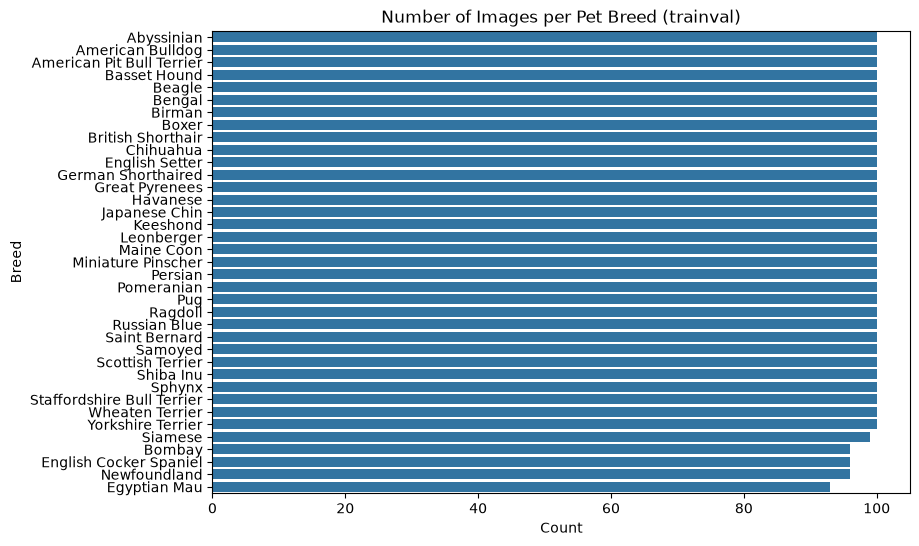

In [104]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 6))
sns.countplot(
    data=df,
    y="breed",
    order=df["breed"].value_counts().index,
)
plt.title("Number of Images per Pet Breed (trainval)")
plt.xlabel("Count")
plt.ylabel("Breed")
plt.show()

Image type: <class 'PIL.Image.Image'>
Image dimensions: (394, 500)
Label: 0


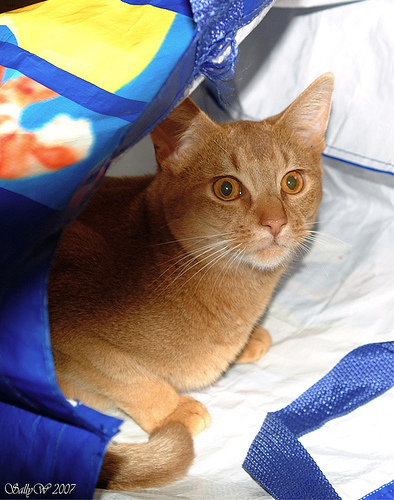

In [108]:
image, label = dataset[0]

print(f"Image type: {type(image)}")
print(f"Image dimensions: {image.size}")
print(f"Label: {label}")

display(image)

In [112]:
import random

random_indices = random.sample(range(len(dataset)), 5)
for idx in random_indices:
    image, label = dataset[idx]
    breed_name = dataset.classes[label]
    print(f"Index: {idx:4d} | Breed: {breed_name:<25} | Dimensions: {image.size} | Mode: {image.mode}")

Index: 2816 | Breed: Leonberger                | Dimensions: (500, 334) | Mode: RGB
Index: 1830 | Breed: Yorkshire Terrier         | Dimensions: (300, 191) | Mode: RGB
Index: 3501 | Breed: Sphynx                    | Dimensions: (500, 327) | Mode: RGB
Index: 2527 | Breed: English Setter            | Dimensions: (500, 333) | Mode: RGB
Index: 1774 | Breed: Wheaten Terrier           | Dimensions: (500, 333) | Mode: RGB
